# 02. Quality Assessment & Filtering

## Overview
This notebook is the **second step** in the pipeline. It analyzes the `quality_score` (Vessel Density) of our dataset images.
We aim to identify low-quality images (blur, poor lighting) that might hinder model training and set a threshold for exclusion.

## Prerequisite
Run `python src/scripts/assess_quality.py` first to compute scores for all images!
(Or rely on the sample computation below if you haven't processed the full dataset yet)


In [10]:
# 1. Setup & Imports
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Add project root
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.config import PROCESSED_DATA_DIR, DATA_DIR
from src.visualization.plots import set_plot_style, _save_plot

set_plot_style()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


['#4B0082', '#762B98', '#A157AE', '#CC82C4', '#FF8C00']

In [11]:
# 2. Load Manifest
manifest_path = PROCESSED_DATA_DIR / "manifest.csv"

if manifest_path.exists():
    df = pd.read_csv(manifest_path)
    print(f"Loaded manifest with {len(df)} images.")
    
    # Check if scores exist
    if 'quality_score' not in df.columns:
        print("\nWARNING: 'quality_score' column missing!")
        print("Please run 'src/scripts/assess_quality.py' to compute scores first.")
    else:
        print("Quality scores found.")
        print(df['quality_score'].describe())
else:
    print("Manifest not found.")

Loaded manifest with 35126 images.
Quality scores found.
count    35126.000000
mean         0.133966
std          0.038480
min          0.000000
25%          0.113641
50%          0.139953
75%          0.160177
max          0.361603
Name: quality_score, dtype: float64


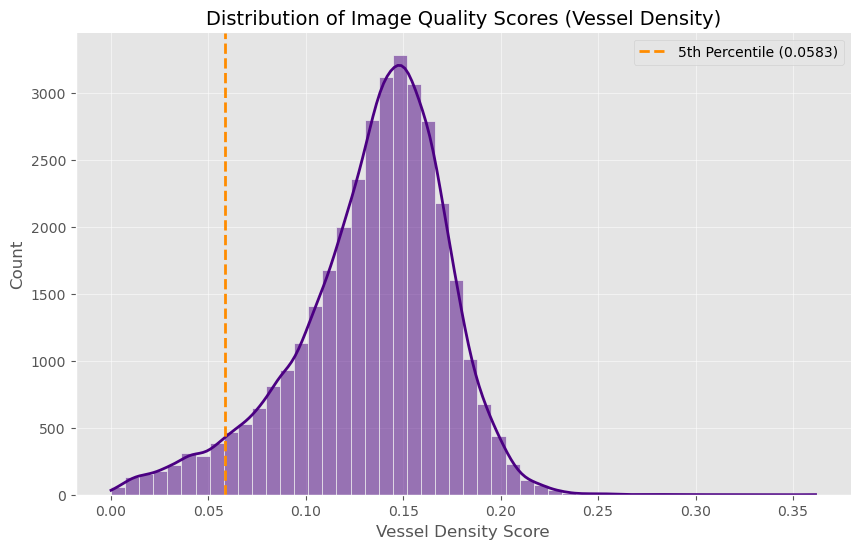

Suggested Threshold (exclude below): 0.0583


In [12]:
# 3. Distribution of Scores
if 'quality_score' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.histplot(df['quality_score'], kde=True, bins=50, color="#4B0082")
    plt.title("Distribution of Image Quality Scores (Vessel Density)")
    plt.xlabel("Vessel Density Score")
    plt.ylabel("Count")
    
    # Determine 5th percentile threshold
    threshold = df['quality_score'].quantile(0.05)
    plt.axvline(threshold, color="#FF8C00", linestyle="--", label=f"5th Percentile ({threshold:.4f})")
    plt.legend()
    plt.show()
    
    print(f"Suggested Threshold (exclude below): {threshold:.4f}")

Displaying low quality examples (below threshold)...


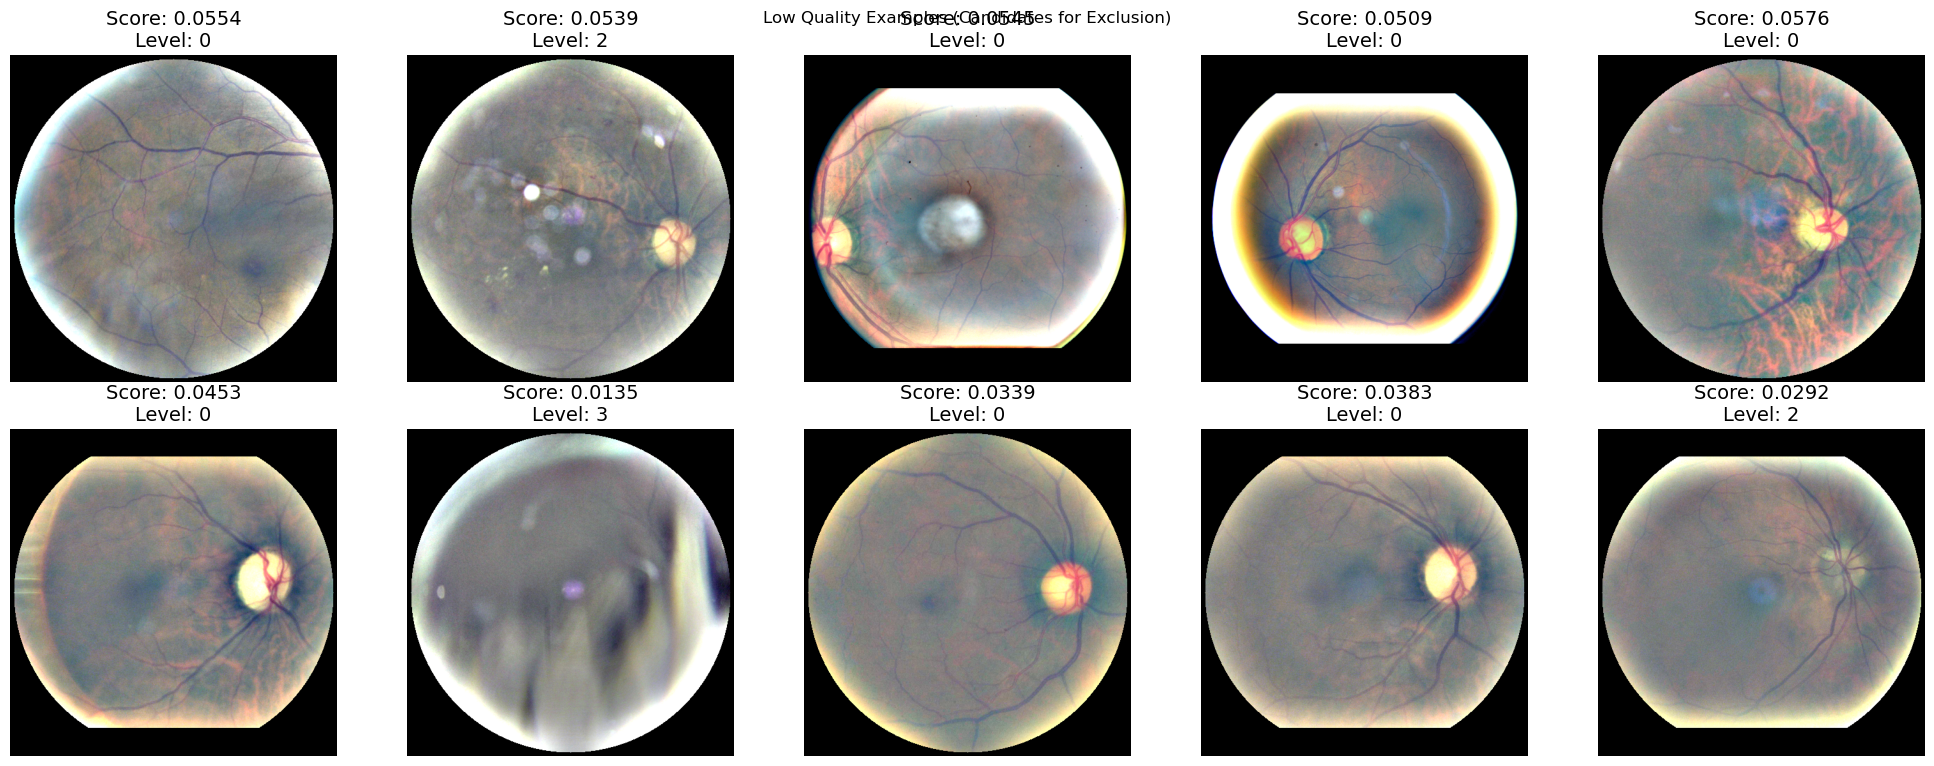

In [13]:
# 4. Visualize Low Quality Examples
if 'quality_score' in df.columns:
    # Sample 10 images for 2 rows
    n_images = 10
    low_quality = df[df['quality_score'] < threshold].sample(n_images)
    print("Displaying low quality examples (below threshold)...")
    
    from src.data.preprocessing import ImagePreprocessor
    preprocessor = ImagePreprocessor()
    
    # Create 2 rows of 5 columns
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()
    
    for i, (_, row) in enumerate(low_quality.iterrows()):
        try:
            original = preprocessor.load_image(row['path'])
            processed = preprocessor.preprocess(original, eye_side=row['eye'])
            
            axes[i].imshow(processed)
            axes[i].set_title(f"Score: {row['quality_score']:.4f}\nLevel: {row['level']}")
        except Exception as e:
            axes[i].text(0.5, 0.5, "Error loading", ha='center')
        axes[i].axis('off')
        
    plt.suptitle("Low Quality Examples (Candidates for Exclusion)", y=0.95)
    plt.tight_layout()
    plt.show()

Displaying high quality examples (above median score)...


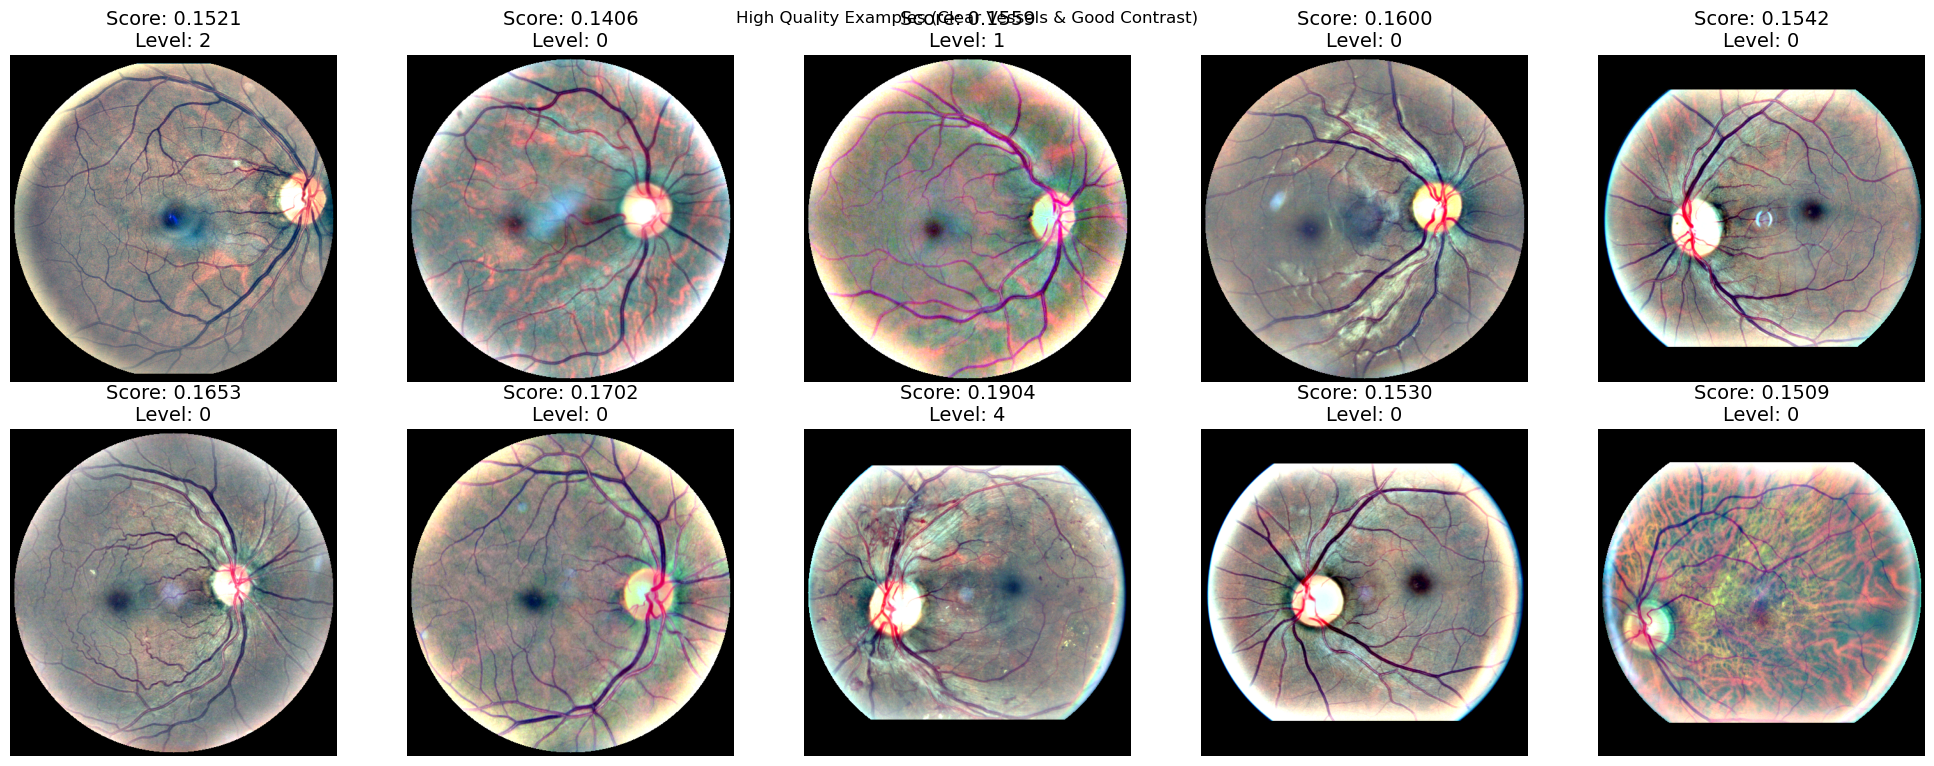

In [14]:
# 4b. Visualize High Quality Examples
if 'quality_score' in df.columns:
    # Sample 10 images for 2 rows of good quality
    n_images = 10
    # Select images well above the threshold (e.g., above median or 75th percentile)
    high_threshold = df['quality_score'].median()
    high_quality = df[df['quality_score'] > high_threshold].sample(n_images)
    print("Displaying high quality examples (above median score)...")
    
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()
    
    for i, (_, row) in enumerate(high_quality.iterrows()):
        try:
            original = preprocessor.load_image(row['path'])
            processed = preprocessor.preprocess(original, eye_side=row['eye'])
            
            axes[i].imshow(processed)
            axes[i].set_title(f"Score: {row['quality_score']:.4f}\nLevel: {row['level']}")
        except Exception as e:
            axes[i].text(0.5, 0.5, "Error loading", ha='center')
        axes[i].axis('off')
        
    plt.suptitle("High Quality Examples (Clear Vessels & Good Contrast)", y=0.95)
    plt.tight_layout()
    plt.show()

In [ ]:
# 5. Connect to Pipeline Config
# We now set the threshold based on our analysis and verify the config matches.

from src.config import QUALITY_THRESHOLD

# Based on histogram and visual check (Cell 4), set your preferred threshold.
# The `src.config` default is set to 5th percentile (approx 0.0583).
CHOSEN_THRESHOLD = QUALITY_THRESHOLD 

print(f"Configured Quality Threshold: {CHOSEN_THRESHOLD}")

# Verify logic using the new loader
try:
    from src.data.make_dataset import load_filtered_dataset
    
    # Load manifest using the helper function
    df_filtered_test = load_filtered_dataset(manifest_path, min_quality_score=CHOSEN_THRESHOLD)
    
    print(f"\n--- Verification ---")
    print(f"Original Count: {len(df)}")
    print(f"Filtered Count: {len(df_filtered_test)}")
    print(f"Removed: {len(df) - len(df_filtered_test)} images ({100 * (len(df) - len(df_filtered_test)) / len(df):.1f}%)")
    
except ImportError:
    print("Could not import `load_filtered_dataset`. Ensure src/data/make_dataset.py is updated.")


Original Count: 35126
Filtered Count: 33803
Removed: 1323 images (3.8%)
Saved filtered manifest to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\data\processed\manifest_filtered.csv


### Next Steps using `load_filtered_dataset`

You have successfully defined the quality threshold. 
When training your model (in `03_model_training.ipynb`), you can now toggle quality filtering by passing this threshold:

```python
from src.data.make_dataset import load_filtered_dataset
from src.config import QUALITY_THRESHOLD

# To train with ONLY high quality images:
train_df = load_filtered_dataset(manifest_path, min_quality_score=QUALITY_THRESHOLD)

# To train with ALL images (disable filtering):
train_df = load_filtered_dataset(manifest_path, min_quality_score=0.0)
```
Proceed to the next notebook in the pipeline.
